# Workstream 3: Pricing and market access
**Client question:** at what price should the client launch (~2028), and how does it get insurers to cover it quickly in the six launch states (TN, KY, IN, OH, MI, WI)?

| Sub-question | Source |
|---|---|
| 3a. What do competitor brands cost per month today, and where should the client sit? | CMS Medicare Part D by Geography and Drug, 2024 |
| 3b. How much is Medicare price negotiation cutting competitor prices by 2028? | CMS Drug Price Negotiation file (Sept 2026) |
| 3c. How do Medicare plans in the six states cover competitor brands (tier, prior authorisation, step therapy)? | CMS Part D formulary file |
| 3d. How far below list price is the real (net) price after rebates? | Public gross-to-net research |
| 3e. What does that mean for revenue (list vs net)? | Workstream 1 targets + 3a-3d |
| 3f. What patient support does the launch need? | Launch lessons (Workstream 2) + research |

**Key terms**
- **List price:** the price the drug maker sets. CMS Part D "drug cost" is close to list price (before rebates).
- **Rebate:** money the drug maker pays back to insurers in exchange for good coverage. Net price = list price minus rebates.
- **Negotiated price (Maximum Fair Price):** the price Medicare now sets for selected high-spend drugs, under the Inflation Reduction Act.

In [1]:
import zipfile, io
import pandas as pd
import matplotlib.pyplot as plt

RAW, OUT, FIG = "../data/raw/", "../data/processed/", "../outputs/"
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 200)
CLIENT_LAUNCH_YEAR = 2028
REGION = ["TN", "KY", "IN", "OH", "MI", "WI"]

## Step 1 (3a): What do competitor brands cost per month?
We use **cost per 30-day fill** rather than cost per prescription, because some prescriptions cover 60 or 90 days. That makes drugs comparable month for month.
- `list_per_month` = total drug cost ÷ 30-day fills (before rebates)
- `patient_pays_per_month` = what Medicare patients paid out of pocket ÷ 30-day fills
- Role: **switch** = replaces the first antidepressant; **add-on** = added on top of it (the client's slot)

In [2]:
geo = pd.read_csv(RAW + "cms_partd_geo_drug.csv", low_memory=False)
us = geo[geo["Prscrbr_Geo_Lvl"] == "National"].copy()

COMPARATORS = {   # brand name in CMS: (label, role)
    "Sertraline Hcl": ("Sertraline (generic)", "First line, generic"),
    "Aripiprazole": ("Aripiprazole (generic)", "Add-on, generic"),
    "Trintellix": ("Trintellix", "Switch, brand"),
    "Fetzima": ("Fetzima", "Switch, brand"),
    "Auvelity": ("Auvelity", "Switch, brand (novel)"),
    "Rexulti": ("Rexulti", "Add-on, brand"),
    "Vraylar": ("Vraylar", "Add-on, brand"),
    "Caplyta": ("Caplyta", "Add-on, brand"),
}
x = us[us["Brnd_Name"].isin(COMPARATORS)].copy()
for c in ["Tot_Clms", "Tot_30day_Fills", "Tot_Drug_Cst", "LIS_Bene_Cst_Shr", "NonLIS_Bene_Cst_Shr"]:
    x[c] = pd.to_numeric(x[c], errors="coerce")
x["drug"] = x["Brnd_Name"].map(lambda b: COMPARATORS[b][0])
x["role"] = x["Brnd_Name"].map(lambda b: COMPARATORS[b][1])
x["list_per_month"] = x["Tot_Drug_Cst"] / x["Tot_30day_Fills"]
x["patient_pays_per_month"] = (x["LIS_Bene_Cst_Shr"].fillna(0) + x["NonLIS_Bene_Cst_Shr"].fillna(0)) / x["Tot_30day_Fills"]
ladder = (x[["drug", "role", "Tot_30day_Fills", "list_per_month", "patient_pays_per_month"]]
          .sort_values("list_per_month").reset_index(drop=True))
ladder.to_csv(OUT + "ws3_price_ladder.csv", index=False)
ladder.round(0)

,drug,role,Tot_30day_Fills,list_per_month,patient_pays_per_month
0,Sertraline (generic),"First line, generic",30157838.0,5.0,1.0
1,Aripiprazole (generic),"Add-on, generic",5417792.0,45.0,4.0
2,Trintellix,"Switch, brand",842087.0,466.0,30.0
3,Fetzima,"Switch, brand",54804.0,493.0,31.0
4,Auvelity,"Switch, brand (novel)",81227.0,949.0,37.0
5,Rexulti,"Add-on, brand",654033.0,1317.0,29.0
6,Vraylar,"Add-on, brand",816427.0,1391.0,14.0
7,Caplyta,"Add-on, brand",166447.0,1612.0,11.0


## Step 2 (3b): How much does Medicare negotiation cut competitor prices?
Under the Inflation Reduction Act, Medicare negotiates prices for its highest-spend drugs. The CMS file lists each selected drug, the year the price starts (`IPAY`) and the negotiated price per 30 days (`Single MFP per 30 DES`).

In [3]:
z = zipfile.ZipFile(RAW + "cms_negotiated_prices.zip")
mfp = pd.read_csv(io.BytesIO(z.read([n for n in z.namelist() if n.endswith(".csv")][0])), dtype=str)
mfp["mfp_per_30"] = pd.to_numeric(mfp["Single MFP per 30 DES"], errors="coerce")
selected = (mfp.groupby(["IPAY", "Selected Drug Name"])["mfp_per_30"].max()
            .reset_index().rename(columns={"IPAY": "price_starts", "Selected Drug Name": "drug"}))
# Depression competitors on the list
dep = selected[selected["drug"].str.upper().str.contains("VRAYLAR|REXULTI|TRINTELLIX|CAPLYTA|AUVELITY")]
dep = dep.assign(list_per_month_2024=dep["drug"].str.title().map(ladder.set_index("drug")["list_per_month"]))
dep["cut_vs_2024_list"] = 1 - dep["mfp_per_30"] / dep["list_per_month_2024"]
dep.round(2)

,price_starts,drug,mfp_per_30,list_per_month_2024,cut_vs_2024_list
22,2027,VRAYLAR,770.0,1390.65,0.45
35,2028,REXULTI,NaN,1316.53,NaN


**How to read this**
- **Vraylar** has a Medicare negotiated price from **January 2027**. Compare it with its 2024 list cost per month above.
- **Rexulti** is selected for **2028**, the client's launch year. Its negotiated price has not been published yet (CMS publishes by 30 November 2026), so it shows as blank.
- Negotiated prices apply to **Medicare only**. Commercial insurers and Medicaid still pay list price minus their own rebates.
- Trintellix, Caplyta and Auvelity are **not** selected.

## Decision: three pricing scenarios (list price per month)
| Scenario | List price | When it fits | Medicare approach |
|---|---|---|---|
| **Premium** | **$1,350** | Phase 3 shows clearly better tolerability (less weight gain, restlessness, sedation) at similar efficacy | Rebate to Part D plans so their real cost lands near Vraylar's $770 negotiated price |
| **Middle** | **$1,050** | Good data, not a standout | Same |
| **Access** | **$850** | Similar tolerability, or speed to coverage matters most | Little rebate needed |

- One list price nationally; Medicare is priced differently through **rebates**, not a separate list price.
- On top of rebates, the maker pays Medicare's **required discount** (10% before, 20% after a patient reaches the yearly out-of-pocket cap) on every Medicare fill. Medicaid gets its legal rebate (at least 23.1%).
- Caplyta ($1,612) is not up for negotiation before ~2029, so it remains the price ceiling.
- Revenue for each scenario is calculated in step 3e.

## Step 3 (3c): How do Medicare plans in the six launch states cover competitor brands today?
Every Medicare drug plan publishes a **formulary** (its list of covered drugs). For each drug the CMS formulary file gives:
- `TIER_LEVEL_VALUE`: the cost-sharing level. Usually 1-2 = generics, 3 = preferred brand, 4 = non-preferred drug, **5 = specialty** (drugs above a monthly cost threshold; patients pay a percentage of the price).
- `PRIOR_AUTHORIZATION_YN`: the doctor must get pre-approval.
- `STEP_THERAPY_YN`: the patient must try another drug first.
- `QUANTITY_LIMIT_YN`: a cap on pills per month (common and usually harmless, e.g. one a day).

**Plans in the region** = Medicare Advantage plans sold in TN, KY, IN, OH, MI or WI, plus stand-alone drug plans (PDPs) sold in the regions that include those states. Each plan counts once; we have no enrollment per plan, so a small plan counts as much as a large one.

**Matching drugs:** the formulary lists drugs by NDC (package code). The first 9 digits identify the maker and product; Vraylar's and Rexulti's codes come from the CMS negotiation file, the others from the makers' product codes.

In [4]:
fz = zipfile.ZipFile(RAW + "cms_partd_formulary_latest.zip")
def read_inner(prefix):
    inner = zipfile.ZipFile(io.BytesIO(fz.read([n for n in fz.namelist() if n.lower().startswith(prefix)][0])))
    return pd.read_csv(inner.open(inner.namelist()[0]), sep="|", dtype=str, encoding="latin-1")

formulary = read_inner("basic drugs")       # one row per formulary x drug
plans = read_inner("plan information")      # one row per plan x county
geo_loc = read_inner("geographic locator")  # county -> state and drug-plan region
print(f"Formulary file: {len(formulary):,} rows, {formulary['FORMULARY_ID'].nunique()} formularies, contract year {formulary['CONTRACT_YEAR'].iloc[0]}")

STATE_NAMES = {"TN": "Tennessee", "KY": "Kentucky", "IN": "Indiana", "OH": "Ohio", "MI": "Michigan", "WI": "Wisconsin"}
plans = plans[plans["PLAN_SUPPRESSED_YN"] == "N"].copy()
for c in ["STATE", "PDP_REGION_CODE"]:
    plans[c] = plans[c].str.strip()
pdp_regions = set(geo_loc.loc[geo_loc["STATENAME"].isin(STATE_NAMES.values()), "PDP_REGION_CODE"].str.strip())
PLAN_KEY = ["CONTRACT_ID", "PLAN_ID", "SEGMENT_ID"]
region_plans = pd.concat([
    plans[plans["STATE"].isin(REGION)],                                         # Medicare Advantage plans in the six states
    plans[(plans["STATE"] == "") & plans["PDP_REGION_CODE"].isin(pdp_regions)],  # stand-alone drug plans covering them
]).drop_duplicates(PLAN_KEY)
all_plans = plans.drop_duplicates(PLAN_KEY)
print(f"Plans in the six-state region: {len(region_plans):,} (of {len(all_plans):,} nationally)")

Formulary file: 1,129,364 rows, 328 formularies, contract year 2026
Plans in the six-state region: 804 (of 5,496 nationally)


In [5]:
PRODUCT_CODES = {   # first 9 digits of the NDC (maker + product)
    "Caplyta":    ["720600110", "720600121", "720600142"],
    "Vraylar":    ["618740115", "618740130", "618740145", "618740160", "618740250", "618740275"],
    "Rexulti":    ["591480035", "591480036", "591480037", "591480038", "591480039", "591480040"],
    "Auvelity":   ["819680045"],
    "Trintellix": ["647640720", "647640730", "647640750"],
}
formulary["product"] = formulary["NDC"].str[:9]
formulary["tier"] = pd.to_numeric(formulary["TIER_LEVEL_VALUE"], errors="coerce")

def coverage(plan_list):
    rows = []
    for drug, codes in PRODUCT_CODES.items():
        d = formulary[formulary["product"].isin(codes)]
        per_formulary = d.groupby("FORMULARY_ID").agg(
            tier=("tier", "min"),
            prior_auth=("PRIOR_AUTHORIZATION_YN", lambda s: (s == "Y").any()),
            step_therapy=("STEP_THERAPY_YN", lambda s: (s == "Y").any()))
        m = plan_list[PLAN_KEY + ["FORMULARY_ID"]].merge(per_formulary, on="FORMULARY_ID", how="left")
        rows.append({"drug": drug,
                     "covered": m["tier"].notna().mean(),
                     "preferred_tier_1_3": (m["tier"] <= 3).mean(),
                     "non_preferred_tier_4": (m["tier"] == 4).mean(),
                     "specialty_tier_5": (m["tier"] >= 5).mean(),
                     "prior_auth": m["prior_auth"].fillna(False).mean(),
                     "step_therapy": m["step_therapy"].fillna(False).mean()})
    out = pd.DataFrame(rows).set_index("drug")
    out.insert(0, "list_per_month", ladder.set_index("drug")["list_per_month"].reindex(out.index).round(0))
    return out

cov_region = coverage(region_plans)
cov_region.to_csv(OUT + "ws3_coverage_region.csv")
def show(t):
    """Percent columns as whole-number percentages, price in dollars."""
    out = t.copy()
    for c in out.columns:
        out[c] = out[c].map("${:,.0f}".format) if c == "list_per_month" else out[c].mul(100).round(0).astype(int).astype(str) + "%"
    return out

print("Share of Medicare plans in the six states (2026 formularies):")
show(cov_region)

Share of Medicare plans in the six states (2026 formularies):


,list_per_month,covered,preferred_tier_1_3,non_preferred_tier_4,specialty_tier_5,prior_auth,step_therapy
drug,,,,,,,
Caplyta,"$1,612",100%,3%,23%,73%,29%,8%
Vraylar,"$1,391",100%,3%,30%,67%,26%,8%
Rexulti,"$1,317",100%,3%,7%,89%,27%,5%
Auvelity,$949,100%,3%,45%,52%,21%,30%
Trintellix,$466,100%,15%,85%,0%,27%,33%


In [6]:
# Is any launch state different? Hurdles by state (Medicare Advantage plans sold in each state)
ma_plans = plans[plans["STATE"].isin(REGION)].drop_duplicates(PLAN_KEY + ["STATE"])
rows = []
for drug, codes in PRODUCT_CODES.items():
    d = formulary[formulary["product"].isin(codes)]
    f_ = d.groupby("FORMULARY_ID").agg(prior_auth=("PRIOR_AUTHORIZATION_YN", lambda s: (s == "Y").any()),
                                       step_therapy=("STEP_THERAPY_YN", lambda s: (s == "Y").any())).reset_index()
    m = ma_plans.merge(f_, on="FORMULARY_ID", how="left")
    by_state = m.groupby("STATE")[["prior_auth", "step_therapy"]].mean()
    by_state["drug"] = drug
    rows.append(by_state.reset_index())
by_state = pd.concat(rows)
national = coverage(all_plans)
for measure in ["prior_auth", "step_therapy"]:
    t = by_state.pivot(index="STATE", columns="drug", values=measure).reindex(REGION)[list(PRODUCT_CODES)]
    t.loc["US (all plans)"] = national[measure]
    print(f"\n{measure.replace('_', ' ').title()}: share of plans, by state")
    print((t * 100).round(0).astype(int).astype(str).add("%").to_string())


Prior Auth: share of plans, by state
drug           Caplyta Vraylar Rexulti Auvelity Trintellix
STATE                                                     
TN                 16%     16%     16%      10%        30%
KY                 42%     41%     41%       8%        19%
IN                 28%     26%     26%      15%        29%
OH                 18%     17%     17%      10%        34%
MI                 44%     44%     44%      56%        24%
WI                 49%     24%     31%      12%        24%
US (all plans)     29%     25%     31%      14%        27%

Step Therapy: share of plans, by state
drug           Caplyta Vraylar Rexulti Auvelity Trintellix
STATE                                                     
TN                  2%      2%      0%      31%        30%
KY                  2%      2%      0%      53%        44%
IN                  3%      3%      0%      31%        26%
OH                  5%      5%      0%      32%        21%
MI                 25%     25%     24

## What 3c tells us
- **Coverage is not the risk.** Every brand is on 100% of Medicare plans: antidepressants and antipsychotics are a protected class, so plans must cover them. Plans show their preferences through **tiers and hurdles** instead.
- **Hurdles follow the drug's role and price, not company size.** Antidepressants (Auvelity, Trintellix) mostly get **step therapy** (try a generic first); antipsychotic add-ons (Caplyta, Vraylar, Rexulti) mostly get **pre-approval**. The hypothesis that a small company faces more hurdles is **partly confirmed**: Auvelity has more step therapy but less pre-approval than Caplyta.
- **The ~$950 a month line matters.** Drugs above it mostly land on the **specialty tier**, where patients pay 25-33% of the price until the yearly cap and cannot appeal for a cheaper tier. Trintellix ($466) is never there; Auvelity ($949) is split; the add-on brands mostly are.
- **Local insurers set the hurdles, and they vary by state.** **Michigan** is the toughest: 44-56% of plans require pre-approval for every brand, driven by regional insurers (Priority Health, Blue Cross Blue Shield of Michigan), and 60% require step therapy for Trintellix. **Kentucky** requires pre-approval for the antipsychotic add-ons on ~41% of plans and step therapy for the antidepressants on 44-53%. Tennessee and Ohio are the easiest.

**So what for the client**
1. Expect full Medicare coverage, but likely **step therapy** if plans treat it as an antidepressant: position and evidence it as an **add-on**.
2. Price above ~$950 means the specialty tier for most plans; the **middle scenario is tested at $1,050 and ~$940** in step 3e.
3. Engage **regional insurers in Michigan and Kentucky** before launch; Tennessee and Ohio are the easiest access states to start strong.

*Limitations: plans are counted equally (no enrollment data); Medicare only, since commercial drug lists are not public.*

## Step 4 (3d): How much of the list price does the client keep?
**Gross-to-net:** list price (gross) minus everything the maker gives back = what it keeps (net). Every piece below is paid by the maker.

| Payer | Share of patients | Discount from list (base) | Test range | Basis |
|---|---|---|---|---|
| Commercial | 65% | 50% | 45-55% | Axsome: Auvelity discounts "high-40%" in 2025, "mid-50%" in Q1 2026; depression is "largely a commercial business" (Q4 2025 call). Includes copay cards |
| Medicare | 20% | 25% = 18% required + 7% voluntary rebate | voluntary 0-25% | Required manufacturer discount (10% / 20% after the patient's yearly cap). Voluntary rebate is a judgment: MedPAC puts average Part D rebates at ~25% of gross (2023), protected classes lower (Milliman) |
| Medicaid | 15% | 35% | 23-51% | 23.1% legal minimum; MACPAC: total Medicaid rebates 51% of gross in FY2023 (incl. inflation penalties a new drug would not owe) |

Payer shares: MEPS 2024 share of antidepressant spending (Medicare 18.5%, Medicaid 13.7%), rounded (Workstream 1).

*Not modelled: 340B hospital discounts and other federal purchaser discounts (e.g. VA), so net revenue may be slightly overstated.*

In [7]:
SCENARIOS = {"Premium": 1350, "Middle": 1050, "Middle-low": 940, "Access": 850}   # list price per month
SPECIALTY_LINE = 950       # Medicare specialty-tier threshold (~$ per month)
PAYER_SHARE = {"commercial": 0.65, "medicare": 0.20, "medicaid": 0.15}
BASE = {"commercial_disc": 0.50, "medicare_required": 0.18, "medicare_voluntary": 0.07, "medicaid_disc": 0.35,
        "medicare_no_subsidy": 0.50,   # share of Medicare patients without the low-income subsidy (estimate)
        "abandon_tier4": 0.30,         # abandonment at a ~$50-100 flat copay (estimate between IQVIA endpoints)
        "abandon_specialty": 0.60,     # IQVIA: branded Rx with >$250 out of pocket, abandonment approaching 60%
        "hurdle_loss": 0.0}            # extra patients lost to insurer hurdles at the Premium price (tested 0-30%)

def blended_discount(a):
    return (PAYER_SHARE["commercial"] * a["commercial_disc"]
            + PAYER_SHARE["medicare"] * (a["medicare_required"] + a["medicare_voluntary"])
            + PAYER_SHARE["medicaid"] * a["medicaid_disc"])

d = blended_discount(BASE)
print(f"Blended discount: {d:.1%} -> the client keeps {1 - d:.1%} of list price")
net = pd.DataFrame({"list_per_month": SCENARIOS})
net["net_per_month"] = (net["list_per_month"] * (1 - d)).round(0)
net

Blended discount: 42.8% -> the client keeps 57.2% of list price


,list_per_month,net_per_month
Premium,1350,773.0
Middle,1050,601.0
Middle-low,940,538.0
Access,850,487.0


### Reality check: does this method reproduce Auvelity's real discount?
Axsome reported Q4 2023 net sales of **$49.0M** on **~84K prescriptions** (Workstream 2 research). Medicare data show ~1.11 months of supply per Auvelity prescription. Dividing net sales by months of supply gives Auvelity's **net price per month**, which we compare with its list cost per month (Step 1).

In [8]:
auv_net_q4_2023, auv_rx_q4_2023 = 49.0e6, 84_000          # Axsome Q4 2023 results
auv = x.set_index("drug").loc["Auvelity"]
months_per_rx = auv["Tot_30day_Fills"] / auv["Tot_Clms"]    # CMS Part D 2024
auv_net_month = auv_net_q4_2023 / (auv_rx_q4_2023 * months_per_rx)
auv_list_month = auv["list_per_month"]
print(f"Auvelity net per month ~${auv_net_month:,.0f} vs list ~${auv_list_month:,.0f} -> implied discount {1 - auv_net_month / auv_list_month:.0%}")
print(f"Our blended assumption: {d:.0%}  (Axsome reported 'high-40%' for 2025)")

Auvelity net per month ~$525 vs list ~$949 -> implied discount 45%
Our blended assumption: 43%  (Axsome reported 'high-40%' for 2025)


*Caveats: prescription counts are rounded, Q4 sales can include wholesaler stocking, and the list price is the 2024 figure. A result in the mid-40s to ~50% means the method is in the right range.*

## Step 5 (3e): Which price earns the most?
**Revenue = patient-months x volume factor x net price per month.**
- **Patient-months:** the Auvelity-based ramp from Workstream 1 (net sales $130.1M in year 1, $291.4M in year 2), converted into months of treatment at Auvelity's net price from the reality check.
- **Volume factor:** starts at 100% (Auvelity's price is at the specialty line, like our Access and Middle-low scenarios), then subtracts two losses for prices above the ~$950 line:
  1. **Copay loss:** Medicare patients without the low-income subsidy face 25-33% of the price on the specialty tier (>$250 a month), where IQVIA finds abandonment approaching 60%, vs ~30% assumed on tier 4.
  2. **Insurer-hurdle loss:** more pre-approval and slower commercial coverage at a higher price. It cannot be measured, so it is **tested from 0% to 40%** for Premium. Other prices above the line take a share in proportion to how far above ~$950 they sit: Middle ($100 above) takes a quarter of Premium's ($400 above) loss.

In [9]:
AUV_NET = {"Year 1": 130.1e6, "Year 2": 291.4e6}
patient_months = {yr: v / auv_net_month for yr, v in AUV_NET.items()}

def volume_factor(price, a):
    if price <= SPECIALTY_LINE:
        return 1.0
    copay_loss = PAYER_SHARE["medicare"] * a["medicare_no_subsidy"] * (a["abandon_specialty"] - a["abandon_tier4"])
    # insurer pushback grows with distance above the line: Premium ($400 above) takes the full loss,
    # Middle ($100 above) takes a quarter of it
    hurdle = a["hurdle_loss"] * (price - SPECIALTY_LINE) / (SCENARIOS["Premium"] - SPECIALTY_LINE)
    return 1 - copay_loss - hurdle

def revenue(a, year="Year 2"):
    k = 1 - blended_discount(a)
    return {s: patient_months[year] * volume_factor(p, a) * p * k / 1e6 for s, p in SCENARIOS.items()}

base = pd.DataFrame({yr: revenue(BASE, yr) for yr in AUV_NET}).round(0)
base.insert(0, "volume_factor", [round(volume_factor(p, BASE), 3) for p in SCENARIOS.values()])
base.insert(0, "net_per_month", net["net_per_month"])
print(f"Patient-months: year 1 ~{patient_months['Year 1']:,.0f}, year 2 ~{patient_months['Year 2']:,.0f}")
print("Net revenue ($M), base case (no insurer-hurdle loss):")
base

Patient-months: year 1 ~247,984, year 2 ~555,438
Net revenue ($M), base case (no insurer-hurdle loss):


,net_per_month,volume_factor,Year 1,Year 2
Premium,773.0,0.97,186.0,416.0
Middle,601.0,0.97,145.0,324.0
Middle-low,538.0,1.00,133.0,299.0
Access,487.0,1.00,121.0,270.0


In [10]:
# Break-even: how many patients can each higher price lose before it earns less than Access?
be = net.copy()
be["break_even_loss_vs_Access"] = (1 - net.loc["Access", "net_per_month"] / net["net_per_month"]).round(2)
print("Share of patients a scenario can lose (vs Access's volume) before earning less than Access:")
be

Share of patients a scenario can lose (vs Access's volume) before earning less than Access:


,list_per_month,net_per_month,break_even_loss_vs_Access
Premium,1350,773.0,0.37
Middle,1050,601.0,0.19
Middle-low,940,538.0,0.09
Access,850,487.0,0.00


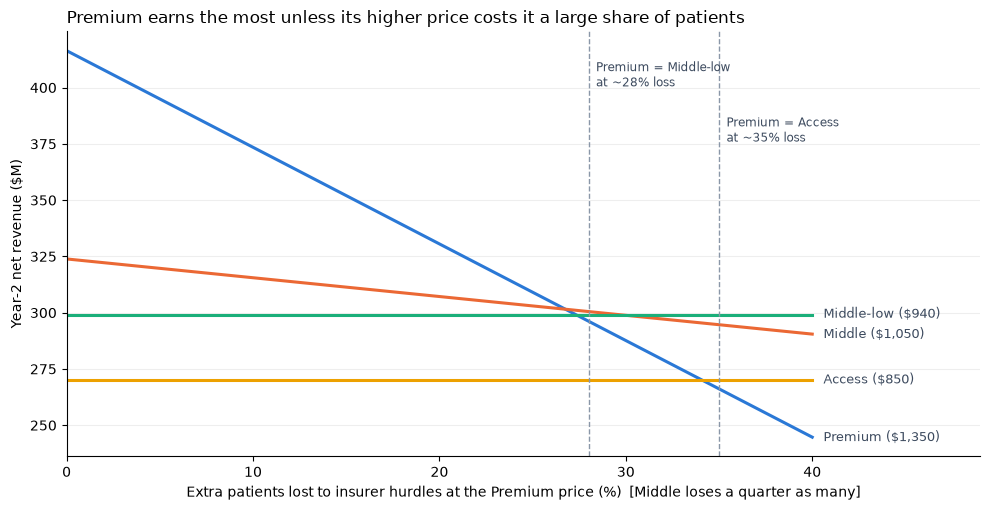

In [11]:
# Year-2 revenue as the insurer-hurdle loss at the Premium price grows from 0% to 40%
losses = [i / 100 for i in range(0, 41)]
curve = pd.DataFrame([revenue({**BASE, "hurdle_loss": h}) for h in losses], index=[h * 100 for h in losses])
COLORS = {"Premium": "#2a78d6", "Middle": "#eb6834", "Middle-low": "#1baf7a", "Access": "#eda100"}

fig, ax = plt.subplots(figsize=(10, 5.2))
for s in SCENARIOS:
    ax.plot(curve.index, curve[s], color=COLORS[s], lw=2.2)
# direct labels at the right end, nudged apart so they do not overlap
ends = curve.iloc[-1].sort_values()
placed = []
for s, v in ends.items():
    y_ = max([v] + [q + 9 for q in placed])
    placed.append(y_)
    ax.text(40.6, y_, f"{s} (${SCENARIOS[s]:,})", va="center", fontsize=9.5, color="#3C4A5E")
for j, other in enumerate(["Middle-low", "Access"]):
    x0 = curve.index[curve["Premium"] <= curve[other]]
    if len(x0):
        ax.axvline(x0[0], color="#8A97A8", lw=1, ls="--")
        ax.text(x0[0] + 0.4, curve["Premium"].max() * (0.99 - 0.06 * j), f"Premium = {other}\nat ~{x0[0]:.0f}% loss", va="top", fontsize=8.5, color="#3C4A5E")
ax.set_xlabel("Extra patients lost to insurer hurdles at the Premium price (%)  [Middle loses a quarter as many]")
ax.set_ylabel("Year-2 net revenue ($M)")
ax.set_xlim(0, 49)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#EEEEEE"); ax.set_axisbelow(True)
ax.set_title("Premium earns the most unless its higher price costs it a large share of patients", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(FIG + "ws3_price_breakeven.png", dpi=200, bbox_inches="tight"); plt.show()

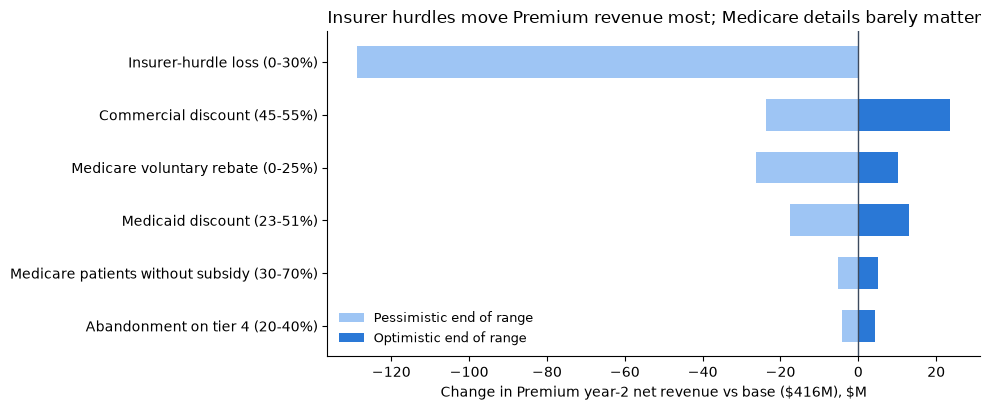

,low,high
assumption,,
Abandonment on tier 4 (20-40%),-4.0,4.0
Medicare patients without subsidy (30-70%),-5.0,5.0
Medicaid discount (23-51%),-17.0,13.0
Medicare voluntary rebate (0-25%),-26.0,10.0
Commercial discount (45-55%),-24.0,24.0
Insurer-hurdle loss (0-30%),-129.0,0.0


In [12]:
# Range test: which assumption moves Premium's year-2 revenue the most? (one at a time, others at base)
TESTS = {"Commercial discount (45-55%)": ("commercial_disc", 0.55, 0.45),
         "Medicare voluntary rebate (0-25%)": ("medicare_voluntary", 0.25, 0.0),
         "Medicaid discount (23-51%)": ("medicaid_disc", 0.51, 0.23),
         "Medicare patients without subsidy (30-70%)": ("medicare_no_subsidy", 0.70, 0.30),
         "Abandonment on tier 4 (20-40%)": ("abandon_tier4", 0.20, 0.40),
         "Insurer-hurdle loss (0-30%)": ("hurdle_loss", 0.30, 0.0)}
base_rev = revenue(BASE)["Premium"]
rows = []
for label, (k, lo, hi) in TESTS.items():
    rows.append({"assumption": label, "low": revenue({**BASE, k: lo})["Premium"] - base_rev,
                 "high": revenue({**BASE, k: hi})["Premium"] - base_rev})
tornado = pd.DataFrame(rows).assign(span=lambda t: t["high"] - t["low"]).sort_values("span")

fig, ax = plt.subplots(figsize=(10, 4.2))
y = range(len(tornado))
ax.barh(y, tornado["low"], color="#9ec5f4", height=0.6, label="Pessimistic end of range")
ax.barh(y, tornado["high"], color="#2a78d6", height=0.6, label="Optimistic end of range")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_yticks(list(y)); ax.set_yticklabels(tornado["assumption"])
ax.axvline(0, color="#3C4A5E", lw=1)
ax.set_xlabel(f"Change in Premium year-2 net revenue vs base (\\${base_rev:,.0f}M), \\$M")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Insurer hurdles move Premium revenue most; Medicare details barely matter", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(FIG + "ws3_sensitivity.png", dpi=200, bbox_inches="tight"); plt.show()
tornado.drop(columns="span").set_index("assumption").round(0)

In [13]:
# Low / base / high: all pessimistic vs all optimistic assumptions together (year-2 net revenue, $M)
LOW = {**BASE, "commercial_disc": 0.55, "medicare_voluntary": 0.25, "medicaid_disc": 0.51,
       "medicare_no_subsidy": 0.70, "abandon_tier4": 0.20, "hurdle_loss": 0.20}
HIGH = {**BASE, "commercial_disc": 0.45, "medicare_voluntary": 0.0, "medicaid_disc": 0.23,
        "medicare_no_subsidy": 0.30, "abandon_tier4": 0.40, "hurdle_loss": 0.0}
cases = pd.DataFrame({"Low": revenue(LOW), "Base": revenue(BASE), "High": revenue(HIGH)}).round(0)
cases.to_csv(OUT + "ws3_revenue_scenarios.csv")
cases

,Low,Base,High
Premium,268.0,416.0,472.0
Middle,250.0,324.0,367.0
Middle-low,251.0,299.0,333.0
Access,227.0,270.0,301.0


## What 3e tells us
**Recommendation: launch at ~\$940 a month by default; move to \$1,350 only if Phase 3 clearly shows better tolerability** than the antipsychotic add-ons (less weight gain, restlessness and drowsiness at similar effectiveness). Phase 3 results arrive in 2027, before the ~2028 launch, so the price can be set with the data in hand.

| Price | Year-2 net revenue (base) | Medicare tier | Role |
|---|---|---|---|
| ~\$940 | ~\$299M | Non-preferred (4): flat copay, appeal possible | **Default**: safe below the ~\$950 specialty-tier line |
| \$1,350 | ~\$416M | Mostly specialty (5): 25-33% coinsurance, no appeal | **If Phase 3 shows clearly better tolerability** |

The safe default gives up ~\$117M of year-2 revenue in exchange for lower access risk while the Phase 3 evidence is pending.

**Answers to the 3e questions**
1. **Is a 28-35% insurer-hurdle loss at \$1,350 likely?** Unlikely. Most hurdles (new company, the ~6-month commercial block, regional insurers in Michigan and Kentucky) hit every price, and pre-approval is roughly flat across brands above the line (Rexulti 27%, Vraylar 26%, Caplyta 29%).
2. **Where should the client focus?** First on insurer acceptance of the price (the only assumption that can flip the decision: up to -\$129M vs a \$117M gap), then on the commercial rebate (+/-\$24M). Medicare and Medicaid details matter but do not change the strategy (\$4-26M).
3. **\$1,050 or ~\$940?** ~\$940. Above the line, hurdles depend on the tier and the drug's role more than the exact price, so \$1,050 would carry Premium's risk with much less revenue.
4. **Recommendation:** as above.

*Limitations: volume follows Auvelity's national ramp (not yet adjusted for a six-state launch, see Workstream 4); one blended discount at every price (a pricier drug may need bigger rebates); revenue, not profit (copay-card and sales costs not included); 340B and federal purchaser discounts not modelled; tier-4 abandonment, the Medicare subsidy share and the insurer-hurdle scaling are estimates.*

## Step 6 (3f): What patient support does the launch need?
**Question:** what does the client offer to help patients get the drug and stay on it, given the hurdles found in 3c?

### What competitors offer (public information, Oct 2026)
| Brand | Copay card (commercial only) | Non-covered / bridge | Pre-approval support | Other support |
|---|---|---|---|---|
| Caplyta (J&J) | As little as \$0; yearly maximum applies | None listed | Mostly self-service: PA guide, payer forms, coverage check | Text program: savings alerts, coverage updates, refill reminders and ordering; \$0 generic antidepressant |
| Rexulti (Otsuka) | \$0 first 2 months, then \$5; up to \$1,200 per use, \$8,180 a year | None listed | Otsuka Patient Support + CoverMyMeds (electronic PA) | Generic antidepressant up to \$100 per 30 days |
| Auvelity (Axsome) | As little as \$10 for up to 90 days | Separate free-trial offer (terms not published) | Least: "talk to your doctor about submitting a request for coverage" | Home-delivery pharmacy (PhilRx), nurse navigator |
| Vraylar (AbbVie) | (covered-patient terms not checked) | **\$75 per 30 days when not covered**, up to 12 fills a year | - | - |

**What it means:** competitors match each other on copay (\$0-10) but offer mostly do-it-yourself pre-approval help. Copay cards are commercial only: the federal anti-kickback statute bars makers from paying copays for Medicare, Medicaid, TRICARE or VA patients.

### Each drop-off reason and the tool that addresses it
| Reason patients do not start or stay on the drug | Client control | Tool |
|---|---|---|
| Claim rejected at the pharmacy (pre-approval not done) | Largely | Pre-approval support: hub + field reimbursement managers |
| Not covered yet (~6-month commercial block) | Largely | Commercial bridge |
| Confusion about coverage, card, next steps | Largely | Support hub |
| Slow effect (4-6 weeks) and early side effects | Partly | Nurse line, check-ins in weeks 1-6, patient materials given at prescribing |
| Cost (Medicare without subsidy, high deductibles) | Partly | Copay card (commercial); Extra Help, payment plan, free-drug program, charities (Medicare) |
| Forgetting, low motivation | Largely / a little | Refill reminders, home delivery |

### Decision: the client's support package
| Component | Level | Why |
|---|---|---|
| **Pre-approval support**: hub (benefits check, forms, appeals) + field reimbursement managers focused on **Michigan and Kentucky** | **Centrepiece** | Biggest barrier (26-56% of Medicare plans in the region require pre-approval); competitors weakest here |
| **Support hub** for all patients: nurse line, refill reminders, home delivery, check-ins in weeks 1-6; Medicare/Medicaid patients routed to Extra Help, the Medicare Prescription Payment Plan, a low-income free-drug program and independent charities | **Strong** | Tackles the non-cost reasons for drop-off and Medicare cost exposure |
| **Commercial bridge** (free or low fixed price while not covered) | First ~6 months after launch | The client starts with zero commercial coverage (Auvelity: 40-48% commercial in year 1) |
| **Copay card** | Match competitors (~\$0-10), with per-fill and yearly limits; debit-card design to monitor maximizers | Expected by doctors and patients; abandonment approaches 60% above \$250 out of pocket (IQVIA) |
| **Generic antidepressant on the card** | Any generic the patient already takes, capped per month | Add-on patients always take one; Caplyta and Rexulti offer it; cheap |
| **App** (pre-approval tracker for patients, value dashboard for doctors' offices) | Phase 2, after launch | Makes the support visible; not a launch priority |
| **Telehealth** | Not included | Regulatory scrutiny of manufacturer-linked telehealth |

**So what:** the hub does not win formulary coverage (rebates and clinical review do); it turns "covered with hurdles" into filled prescriptions. The client starts like Auvelity (new, mid-size, zero coverage), so pull-through support matters more for it than for Caplyta, whose coverage came from earlier approvals.

*Design guardrails for the deck: patient consent and aggregated practice-level data (HIPAA); present services as access support, not an incentive to prescribe. Accumulators and maximizers affect ~43-47% of commercial lives (IQVIA); Tennessee and Kentucky ban accumulators for state-regulated plans (Avalere).*